In [22]:
# Manual check of carrier removal: current vs masked vs subtract-first, one wavelength at a time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from phase_shift import PhaseConfig, PhaseSolver, remove_carrier, subtract_reference
from phase_shift.backend import asnumpy
from compare_carrier_removal import rob, correct, box_mean

root = Path("/Users/rodionsa/KAUST Dropbox/Sergei Rodionov/Lab_measurements_shared/HoloEML/20261019_wvl_stack_500_700_5")
wl = 700   # nm
N = 10

black = np.load(next(root.glob("*_black_*.npz")))["black"]
m = black.mean(0)
bad = rob(m) | rob(black.std(0))

In [23]:
# Fit sample and reference once; sample-arm intensities (no fringes) for the mask
method_kwargs = {"iters": 30, "tol": 1e-4,
                 "basis": "poly", "basis_kwargs": {"degree": 2},
                 "orders": 3, "order_tol": 0.0, "crop": 100}
config = PhaseConfig(use_alpha=True, gain_mode="joint", method="vp_aia",
                     method_kwargs=method_kwargs, phi_error_simplified=True)
solver = PhaseSolver(config, precision="single")

with np.load(next(root.glob(f"*_{wl}nm_*.npz"))) as d:
    sample = d[d.files[1]][0, :N]
    ref = d[d.files[4]][0, :N]
    I_s = correct(d[d.files[3]] - m, bad).mean(0)   # sample arm at the sample position
    I_r = correct(d[d.files[6]] - m, bad).mean(0)   # sample arm at the reference position

rs = solver.fit(correct(sample - m, bad)).result
rr = solver.fit(correct(ref - m, bad)).result
phi_s, b_s = asnumpy(rs.phi), np.abs(asnumpy(rs.b))
phi_r, b_r = asnumpy(rr.phi), np.abs(asnumpy(rr.b))

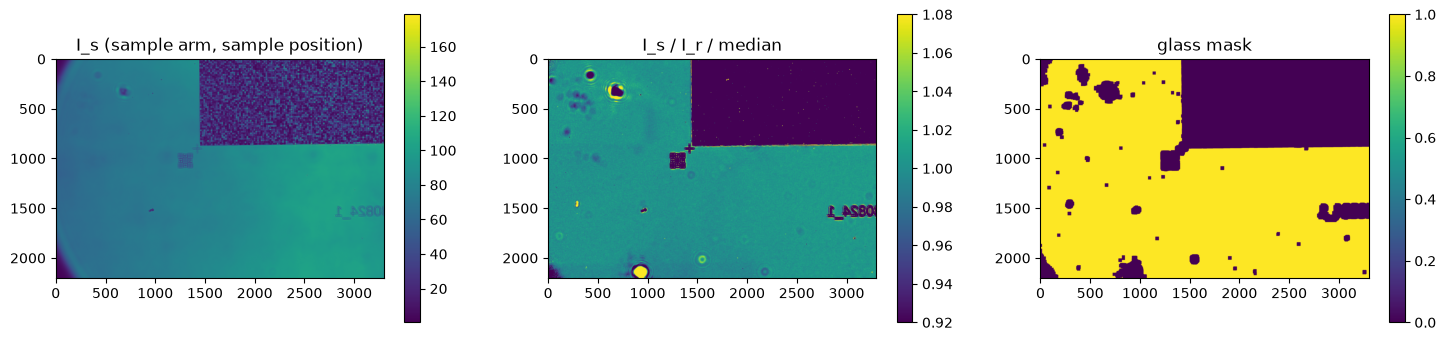

glass fraction: 0.71


In [24]:
# Glass mask from the transmission map I_s / I_r (no fringes): structures deviate from the
# glass level by more than thr, grown by `grow` px. Or replace `glass` by your own boolean (H, W) array
thr, grow = 0.04, 15
T_map = box_mean(I_s/np.maximum(I_r, 1e-6), 2)
T_map /= np.median(T_map)
glass = box_mean((np.abs(T_map - 1) > thr).astype(float), grow) == 0

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, img, title, clim in zip(ax, [I_s, T_map, glass],
                               ["I_s (sample arm, sample position)", "I_s / I_r / median", "glass mask"],
                               [(None, None), (1 - 2*thr, 1 + 2*thr), (0, 1)]):
    im = a.imshow(img, vmin=clim[0], vmax=clim[1])
    a.set_title(title)
    plt.colorbar(im, ax=a)
plt.show()
print(f"glass fraction: {glass.mean():.2f}")

In [31]:
# Three approaches
out = {
    "current": subtract_reference(remove_carrier(phi_s, b_s, degree=2).phi,
                                  remove_carrier(phi_r, b_r, degree=2).phi, b_r).phi,
    "masked": subtract_reference(remove_carrier(phi_s, b_s, mask=glass, degree=2).phi,
                                 remove_carrier(phi_r, b_r, mask=glass, degree=2).phi,
                                 b_r, mask=glass).phi,
    "sub_first": subtract_reference(phi_s, phi_r, b_r, mask=glass).phi,
}
out = {k: asnumpy(v) for k, v in out.items()}

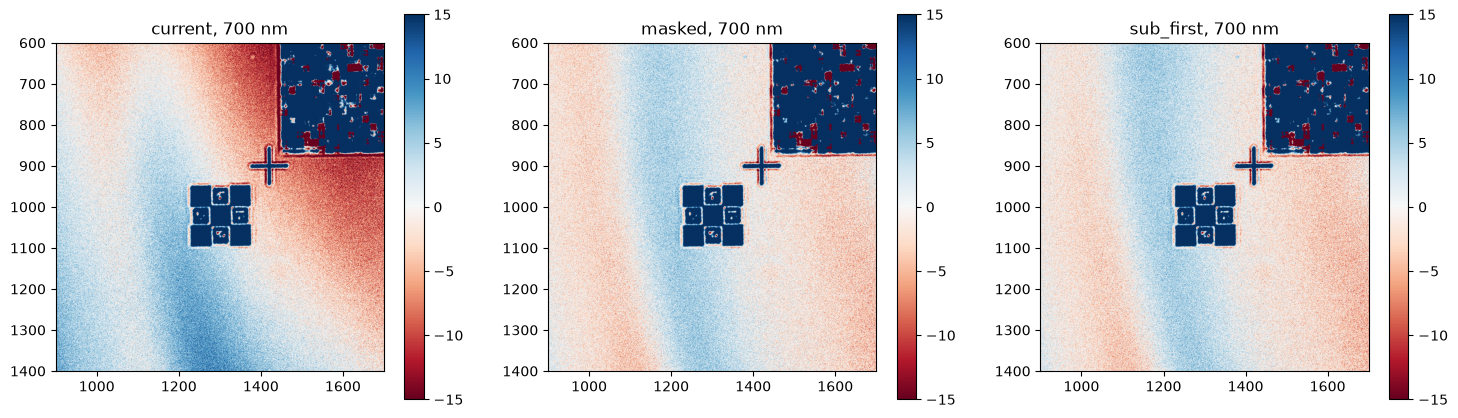

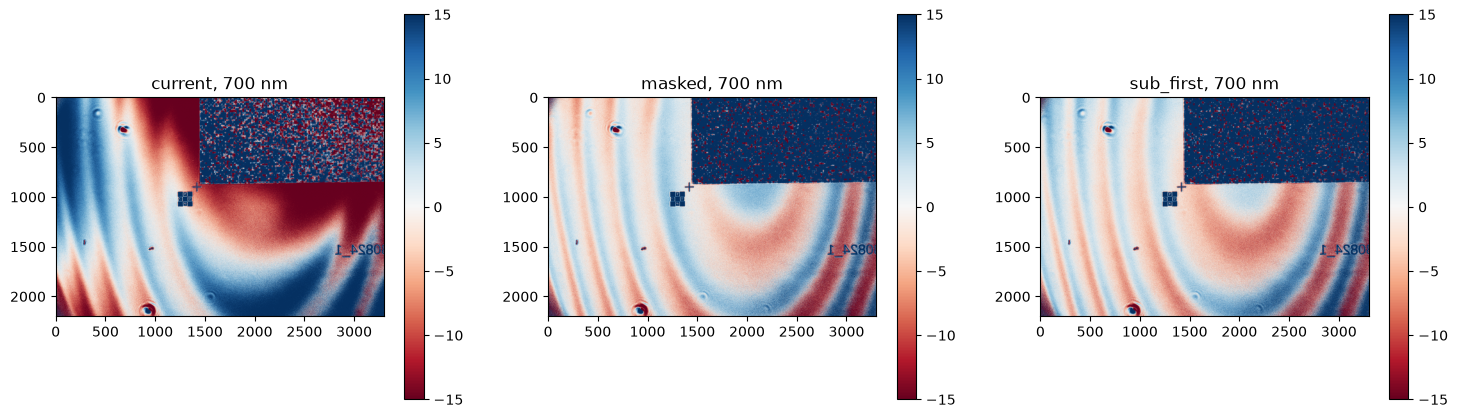

In [32]:
def show(xlim=(900, 1700), ylim=(1400, 600), clim=15, glass_only=False):
    """Phase maps (deg) of the three approaches, piston removed on glass inside the view."""
    sl = (slice(min(ylim), max(ylim)), slice(min(xlim), max(xlim)))
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    for a, (name, phi) in zip(ax, out.items()):
        z = np.exp(1j*phi)
        x = np.degrees(np.angle(z*np.conj(z[sl][glass[sl]].mean())))
        im = a.imshow(np.where(glass, x, np.nan) if glass_only else x, cmap="RdBu", vmin=-clim, vmax=clim)
        a.set_xlim(xlim); a.set_ylim(ylim)
        a.set_title(f"{name}, {wl} nm")
        plt.colorbar(im, ax=a)
    plt.show()

show()                                    # around the patch array
show(xlim=(0, 3300), ylim=(2200, 0))      # full field

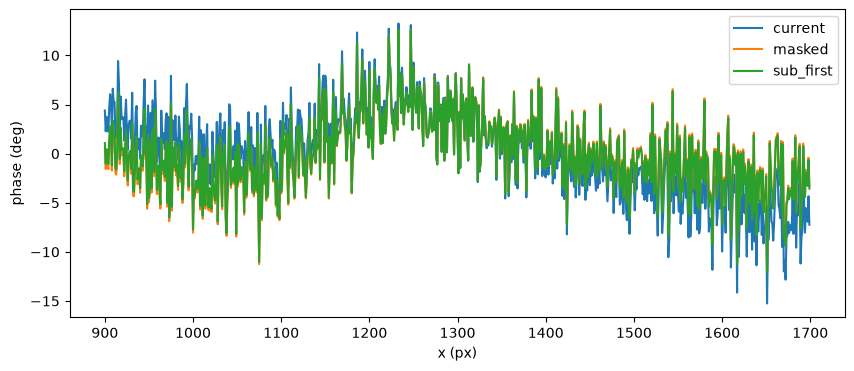

In [33]:
# Line profile through the glass, all three approaches
y_line, xr = 1200, (900, 1700)
plt.figure(figsize=(10, 4))
for name, phi in out.items():
    z = np.exp(1j*phi[y_line, xr[0]:xr[1]])
    plt.plot(np.arange(*xr), np.degrees(np.angle(z*np.conj(z.mean()))), label=name)
plt.xlabel("x (px)"); plt.ylabel("phase (deg)"); plt.legend()
plt.show()

glass rms before 8.03 deg, after 5.60 deg


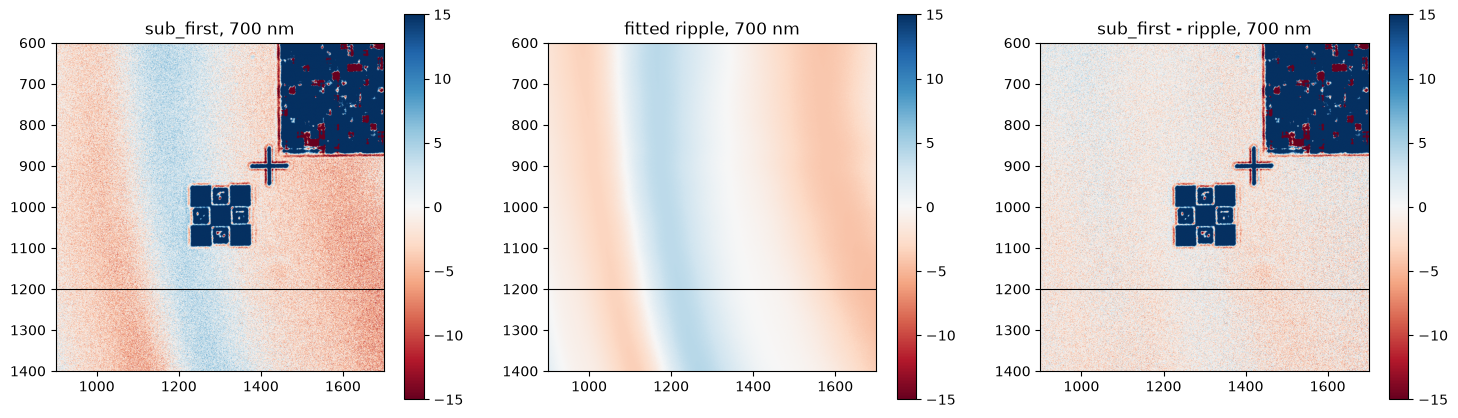

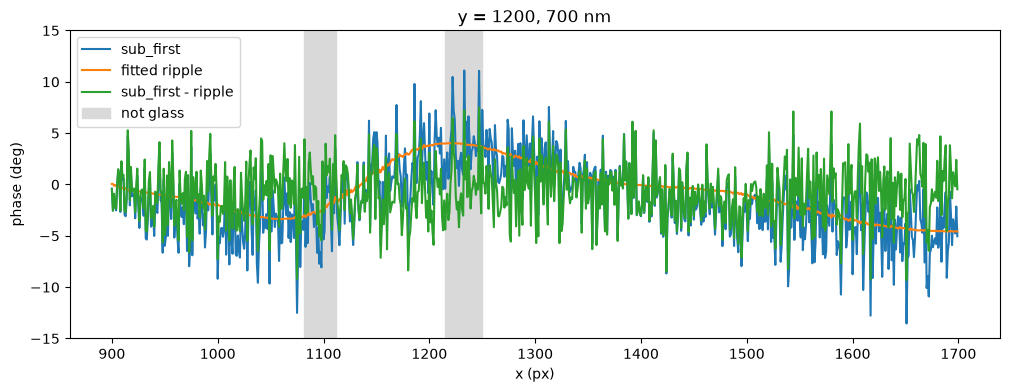

In [53]:
# Fringe-leakage removal: fit harmonics of the carrier phase psi (raw reference phase) on glass,
# optionally modulated by a polynomial in x, y, and subtract the fitted ripple everywhere
src = "sub_first"   # or "masked"
K = 2               # harmonics cos(k psi), sin(k psi), k = 1..K
poly_deg = 3        # polynomial modulation of the ripple amplitude (0 = constant)
step = 4            # subsampling of the fit

H, W = phi_r.shape
psi = phi_r
z = np.exp(1j*out[src])
x = np.angle(z*np.conj(z[glass].mean()))     # glass piston removed, rad

def terms(sl):
    """Basis terms on the pixels sl: piston, then harmonic x monomial products."""
    yy, xx = np.mgrid[0:H, 0:W]
    Y, X = (yy[sl] - H/2)/(H/2), (xx[sl] - W/2)/(W/2)
    mono = [X**i*Y**j for i in range(poly_deg + 1) for j in range(poly_deg + 1 - i)]
    yield np.ones_like(X)
    for k in range(1, K + 1):
        for f in (np.cos, np.sin):
            h = f(k*psi[sl])
            for mo in mono:
                yield h*mo

sub = (slice(0, H, step), slice(0, W, step))
g = glass[sub]
A = np.stack([t[g] for t in terms(sub)], -1)          # (P_glass, n_terms)
c, *_ = np.linalg.lstsq(A, x[sub][g], rcond=None)

ripple = np.zeros((H, W))
for i, (ci, t) in enumerate(zip(c, terms((slice(None), slice(None))))):
    if i:                                             # skip the piston
        ripple += ci*t
clean = np.angle(np.exp(1j*(x - ripple)))
print(f"glass rms before {np.degrees(x[glass].std()):.2f} deg, after {np.degrees(clean[glass].std()):.2f} deg")

xlim, ylim, clim = (900, 1700), (1400, 600), 15
y_prof = 1200       # row of the line profile
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, img, title in zip(ax, [x, ripple, clean], [f"{src}", "fitted ripple", f"{src} - ripple"]):
    im = a.imshow(np.degrees(img), cmap="RdBu", vmin=-clim, vmax=clim)
    a.set_xlim(xlim); a.set_ylim(ylim)
    a.hlines(y_prof, *xlim, color="k", lw=0.8)
    a.set_title(f"{title}, {wl} nm")
    plt.colorbar(im, ax=a)
plt.show()

# Line profile along y_prof (black line above); grey: pixels outside the glass mask
xs = np.arange(*xlim)
row = (y_prof, slice(*xlim))
plt.figure(figsize=(12, 4))
for img, label in zip([x, ripple, clean], [src, "fitted ripple", f"{src} - ripple"]):
    plt.plot(xs, np.degrees(img[row]), label=label)
plt.fill_between(xs, -clim, clim, where=~glass[row], color="0.85", label="not glass")
plt.ylim(-clim, clim)
plt.xlabel("x (px)"); plt.ylabel("phase (deg)"); plt.title(f"y = {y_prof}, {wl} nm")
plt.legend()
plt.show()

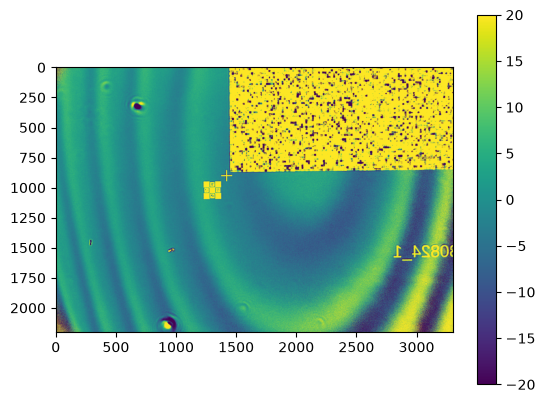

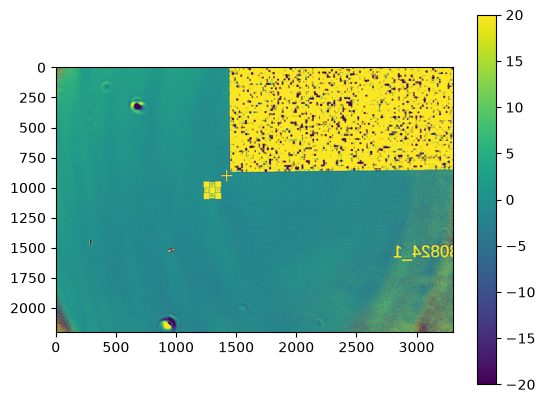

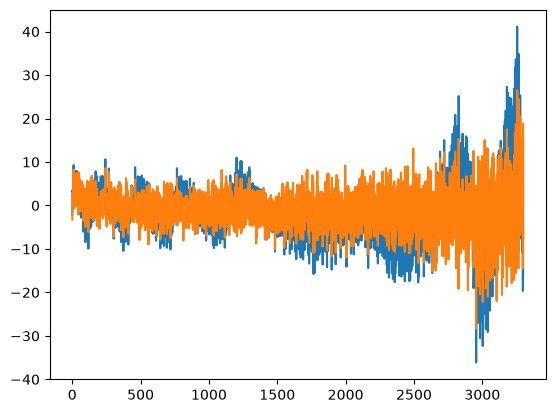

In [54]:
plt.figure()
plt.imshow(x*180/np.pi)
plt.clim([-20, 20])
plt.colorbar()
plt.show()

plt.figure()
plt.imshow(clean*180/np.pi)
plt.clim([-20, 20])
plt.colorbar()
plt.show()

plt.figure()
plt.plot(x[1250]*180/np.pi)
plt.plot(clean[1250]*180/np.pi)
plt.show()